<a href="https://colab.research.google.com/github/TZBDragon/LinAlg344TZB/blob/main/notebooks/01_image_as_matrix_ipynb_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Basic image manipulation techniques and numpy basics

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
A = data.camera()

Imports

In [ ]:
print("Shape:", A.shape)
print("Data type:", A.dtype)
print("Smallest entry:", A.min())
print("Largest entry:", A.max())
print("Top-left 3 x 3 block:\n", A[:3, :3])

Shape: (512, 512)
Data type: uint8
Smallest entry: 0
Largest entry: 255
Top-left 3 x 3 block:
 [[200 200 200]
 [200 199 199]
 [199 199 199]]


Look at shape size of the camera image

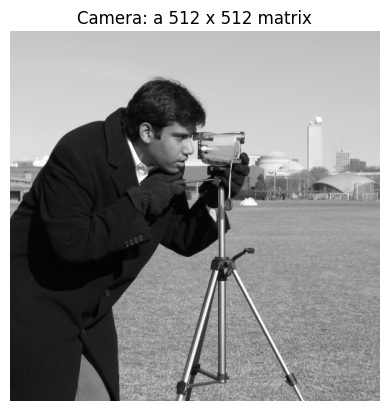

In [ ]:
plt.imshow(A, cmap="gray", vmin=0, vmax=255)
plt.title("Camera: a 512 x 512 matrix")
plt.axis("off")
plt.show()

show the image

Color image shape: (512, 512, 3)


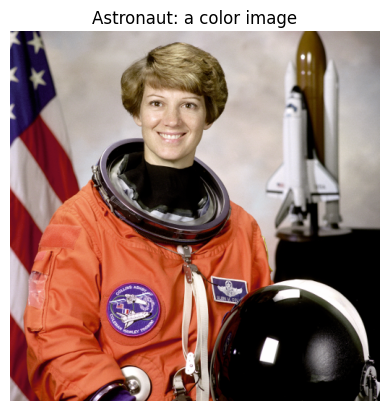

In [ ]:
C = data.astronaut()
print("Color image shape:", C.shape)
plt.imshow(C)
plt.title("Astronaut: a color image")
plt.axis("off")
plt.show()

same for the astronaut

In [ ]:
R = C[:, :, 0] # red channel
G = C[:, :, 1] # green channel
B = C[:, :, 2] # blue channel
print("Red channel shape:", R.shape)
print("Green channel shape:", G.shape)
print("Blue channel shape:", B.shape)

Red channel shape: (512, 512)
Green channel shape: (512, 512)
Blue channel shape: (512, 512)


pull out the color channels

In [ ]:
x = np.array([200], dtype=np.uint8)
y = np.array([100], dtype=np.uint8)
print("uint8 200 + 100 =", x + y)
print("float 200 + 100 =", x.astype(float) + y.astype(float))

uint8 200 + 100 = [44]
float 200 + 100 = [300.]


Show that uints can overflow

In [ ]:
cross = np.array([
[0, 1, 1, 0],
[1, 1, 1, 1],
[1, 1, 1, 1],
[0, 1, 1, 0]
])
gradient = np.array([
[i + j for j in range(4)]
for i in range(4)
])
checker = np.array([
[(i + j + 1) % 2 for j in range(4)]
for i in range(4)
])

create some basic images with easy to recognize patterns

In [ ]:
print("Cross rank =", np.linalg.matrix_rank(cross))
print("Gradient rank =", np.linalg.matrix_rank(gradient))
print("Checkerboard rank =", np.linalg.matrix_rank(checker))

Cross rank = 2
Gradient rank = 2
Checkerboard rank = 2


get rank of those patterns

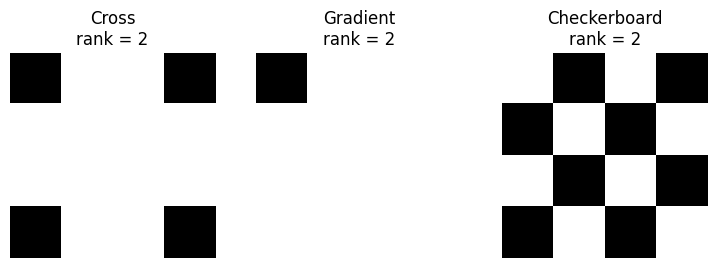

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
images = [("Cross", cross), ("Gradient", gradient),
("Checkerboard", checker)]
for ax, (name, M) in zip(axes, images):
  ax.imshow(M, cmap="gray", vmin=0, vmax=1)
  ax.set_title(f"{name}\nrank = {np.linalg.matrix_rank(M)}")
  ax.axis("off")
plt.show()

show the easy to recognize patterns

[[1 1 1 1]
 [0 0 0 0]
 [1 1 1 1]
 [0 0 0 0]]
Rank = 1


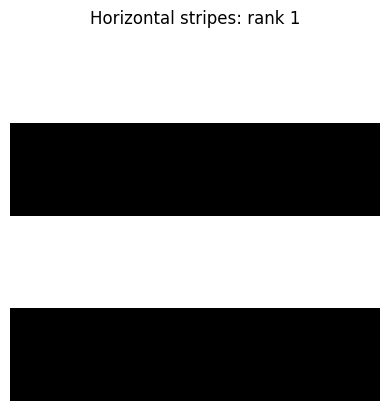

In [ ]:
u = np.array([1, 0, 1, 0])
v = np.array([1, 1, 1, 1])
stripes = np.outer(u, v)
print(stripes)
print("Rank =", np.linalg.matrix_rank(stripes))
plt.imshow(stripes, cmap="gray", vmin=0, vmax=1)
plt.title("Horizontal stripes: rank 1")
plt.axis("off")
plt.show()

make and show an image of horzontal stripes

In [ ]:
from google.colab import files
from PIL import Image
import os
import subprocess
import sys
USER = 'tzbdragon'
REPO = 'LinAlg344TZB'
if os.path.exists(REPO):
  subprocess.run(['git', '-C', REPO, 'pull'], check=True)
else:
  subprocess.run(
  ['git', 'clone', f'https://github.com/{USER}/{REPO}.git', REPO],
  check=True)
sys.path.insert(0, f'{REPO}/src')

imports

Shape: (4016, 6016)
Data type: float64


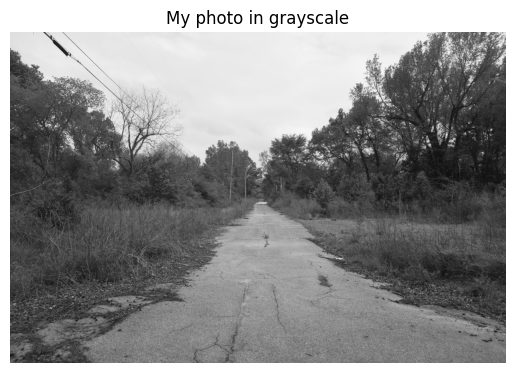

In [ ]:
P = np.array(Image.open(f"{REPO}/data/TZB_7471.JPG").convert('L')).astype(float)
print("Shape:", P.shape)
print("Data type:", P.dtype)
plt.imshow(P, cmap="gray", vmin=0, vmax=255)
plt.title("My photo in grayscale")
plt.axis("off")

5

plt.show()

My image imported and Displayed

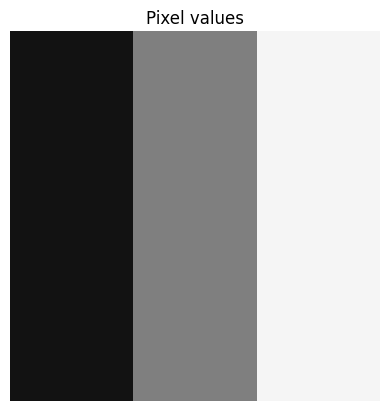

In [ ]:
pixelValues = np.array([[18, 127, 245],
                       [18, 127, 245],
                       [18, 127, 245]])
plt.imshow(pixelValues, cmap="gray", vmin=0, vmax=255)
plt.title("Pixel values")
plt.axis("off")
plt.show()
# As can be seen below 18 is nearly black, 12 is a middle grey, and 245 is nearly white


2. 600 columns, 900 rows, 3 color channels. 1620000 ints are used to describe the image

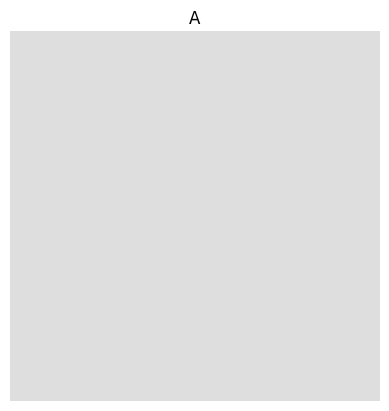

In [ ]:
A = P[:5, :5]
plt.imshow(A, cmap="gray", vmin=0, vmax=255)
plt.title("A")
plt.axis("off")
plt.show()
# First colon selects rows, second selects columns

top 5x5 square of my image

In [ ]:
num1 = np.array([240], dtype=np.uint8)
num2 = np.array([20], dtype=np.uint8)
print("uint8 240 + 20 =", num1 + num2) # The 8 bit unsigned overflows as it's max is 255
print("float 240 + 20 =", num1.astype(float) + num2.astype(float)) #Floats do not overflow as they are 32 bit and can represent many more numbers


uint8 240 + 20 = [4]
float 240 + 20 = [260.]


ints overflowing again

Rank = 4


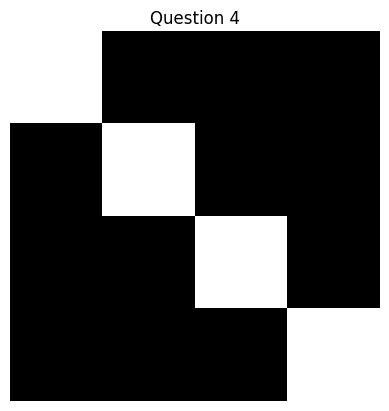

In [ ]:
question4 = np.array([[1,0,0,0],[0,1,0,0],[0,0,1,0],[0,0,0,1]])
plt.imshow(question4, cmap="gray", vmin=0, vmax=1)
plt.title("Question 4")
plt.axis("off")
print("Rank =", np.linalg.matrix_rank(question4))
plt.show()
#Rank 4 becuase I picked linearly independent vectors

I don't need to guess as I purposefully picked an array that would be full rank

Matrix:
 [[200 200 200 200]
 [ 50  50  50  50]
 [150 150 150 150]
 [  0   0   0   0]]
Rank = 1


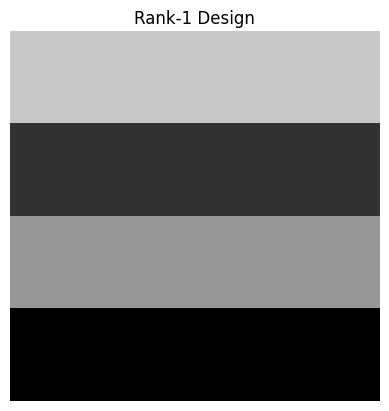

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Choose two vectors with smaller values so the outer product entries stay in [0, 255]
u = np.array([200, 50, 150, 0])
v = np.array([1, 1, 1, 1])  # Keeping v as ones shows horizontal stripes where each row is a multiple of [1, 1, 1, 1]

stripes = np.outer(u, v)
print("Matrix:\n", stripes)
print("Rank =", np.linalg.matrix_rank(stripes))

# Display the image properly scaled
plt.imshow(stripes, cmap="gray", vmin=0, vmax=255)
plt.title("Rank-1 Design")
plt.axis("off")
plt.show()
# Explanation: Every row is a scalar multiple of the vector v^T. Since all rows
# are linearly dependent (multiples of a single row pattern), the rank of this matrix is exactly 1.

200 is a light grey, 50 is a dark grey, and 150 is middle grey.

What we found: 1